# Step 5. EDA & Visualization — Flight Distance Analysis

## Objective

This notebook explores the relationship between flight distance and arrival delays for flights departing from New York City airports in 2013.

We examine flight distance distributions, compare arrival delay statistics across five distance groups, and analyze the frequency of moderate and severe delays.

This analysis builds on the cleaned dataset from Step 3 and the descriptive statistics from Step 4. The results are exploratory and do not establish causation.

## 1. Load & Validate Data

Load the cleaned flight dataset and check for missing values, invalid distances, and missing arrival delays.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

# File paths
data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# Load cleaned dataset
analysis = pd.read_csv(data_path)

print("Dataset shape:", analysis.shape)
print("Missing distance:", analysis["distance"].isna().sum())
print("Missing arrival delay:", analysis["arr_delay"].isna().sum())
print("Invalid distance:", (analysis["distance"] <= 0).sum())

# Keep valid observations
distance_data = analysis.loc[
    analysis["distance"].notna()
    & (analysis["distance"] > 0)
    & analysis["arr_delay"].notna()
].copy()

print("Valid observations:", f"{len(distance_data):,}")
print("Excluded observations:", f"{len(analysis) - len(distance_data):,}")

display(distance_data[["distance", "arr_delay"]].head())

Dataset shape: (327346, 34)
Missing distance: 0
Missing arrival delay: 0
Invalid distance: 0
Valid observations: 327,346
Excluded observations: 0


,distance,arr_delay
0,1400,11.0
1,1416,20.0
2,1089,33.0
3,1576,-18.0
4,762,-25.0


## 2. Distance Descriptive Statistics

Summarize flight distances and arrival delays using descriptive statistics.

We also compare the overall mean and median arrival delays to understand how large delays may affect the average.

In [2]:
distance_summary = distance_data[
    ["distance", "arr_delay"]
].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(distance_summary.round(2))

print(
    f"Mean flight distance: "
    f"{distance_data['distance'].mean():.2f} miles"
)

print(
    f"Mean arrival delay: "
    f"{distance_data['arr_delay'].mean():.2f} minutes"
)

print(
    f"Median arrival delay: "
    f"{distance_data['arr_delay'].median():.2f} minutes"
)

,distance,arr_delay
count,327346.00,327346.00
mean,1048.37,6.90
std,735.91,44.63
min,80.00,-86.00
10%,214.00,-26.00
25%,509.00,-17.00
50%,888.00,-5.00
75%,1389.00,14.00
90%,2446.00,52.00
95%,2475.00,91.00


Mean flight distance: 1048.37 miles
Mean arrival delay: 6.90 minutes
Median arrival delay: -5.00 minutes


## 3. Flight Distance Distribution

Visualize the distribution of flight distances to understand the range and frequency of routes represented in the dataset.

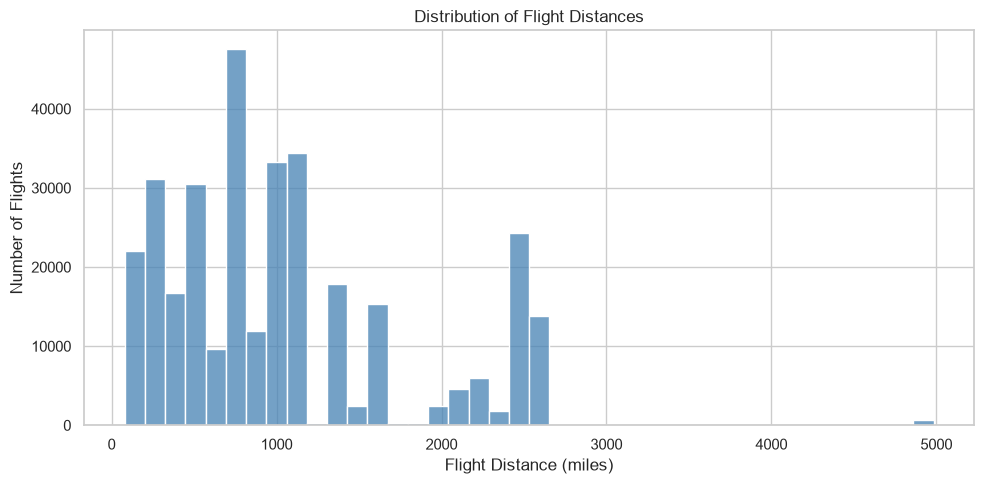

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=distance_data,
    x="distance",
    bins=40,
    color="steelblue",
    ax=ax
)

ax.set(
    title="Distribution of Flight Distances",
    xlabel="Flight Distance (miles)",
    ylabel="Number of Flights"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Arrival Delays by Distance Group

Divide flights into five distance groups and compare the number of flights, mean delay, median delay, standard deviation, and delay rates.

The distance groups follow the categories used in the original distance analysis. They are exploratory categories rather than official industry classifications.

In [4]:
distance_bins = [0, 500, 1000, 1500, 2000, 5000]

distance_labels = [
    "0-500",
    "501-1000",
    "1001-1500",
    "1501-2000",
    "2001+"
]

distance_data["distance_group"] = pd.cut(
    distance_data["distance"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=False,
    right=True
)

# Check that all observations are assigned
unassigned = distance_data["distance_group"].isna().sum()

print("Unassigned distance groups:", unassigned)

assert unassigned == 0, (
    "Some flights fall outside the defined distance groups."
)

distance_stats = (
    distance_data.groupby(
        "distance_group",
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(distance_labels)
)

display(distance_stats.round(2))

assert distance_stats["Flights"].sum() == len(distance_data)

print("Distance group statistics calculated successfully!")

Unassigned distance groups: 0


,Flights,Mean,Median,Std,Min,Max,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
distance_group,,,,,,,,,
0-500,76775,9.26,-5.0,44.23,-62.0,1127.0,24.61,9.70,3.38
501-1000,105819,9.10,-4.0,46.17,-63.0,1109.0,24.83,9.17,3.46
1001-1500,72798,5.62,-5.0,43.86,-68.0,931.0,23.22,7.83,2.79
1501-2000,20772,5.16,-5.0,42.43,-68.0,847.0,23.30,7.49,2.54
2001+,51182,1.31,-7.0,43.35,-86.0,1272.0,20.93,6.61,2.38


Distance group statistics calculated successfully!


### Mean vs. Median Arrival Delay by Distance Group

Compare mean and median arrival delays across distance groups to examine differences in typical delays and the possible influence of extreme values.

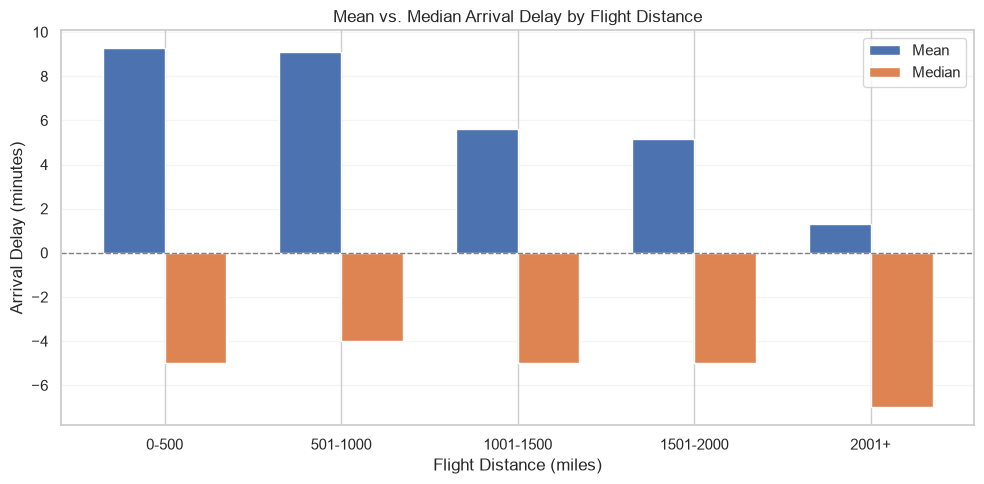

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(distance_labels))
width = 0.35

ax.bar(
    x - width / 2,
    distance_stats["Mean"],
    width,
    label="Mean"
)

ax.bar(
    x + width / 2,
    distance_stats["Median"],
    width,
    label="Median"
)

ax.set_xticks(x)
ax.set_xticklabels(distance_labels)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Mean vs. Median Arrival Delay by Flight Distance",
    xlabel="Flight Distance (miles)",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_mean_vs_median.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Delay Rates by Distance Group

Compare the percentages of flights delayed more than 15, 60, and 120 minutes across distance groups.

These measures help us understand whether different flight distances are associated with moderate or severe arrival delays.

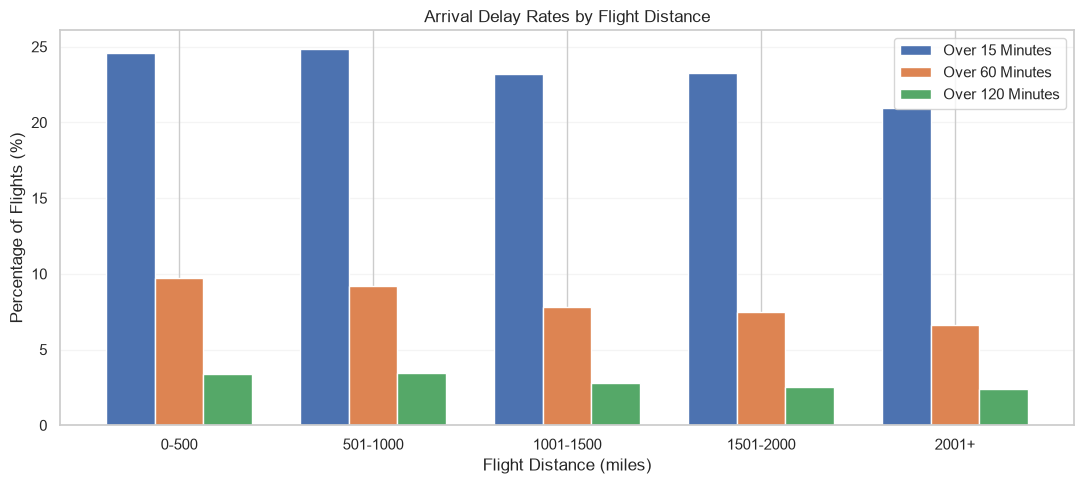

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(distance_labels))
width = 0.25

ax.bar(
    x - width,
    distance_stats["Delay_Over_15_Pct"],
    width,
    label="Over 15 Minutes"
)

ax.bar(
    x,
    distance_stats["Delay_Over_60_Pct"],
    width,
    label="Over 60 Minutes"
)

ax.bar(
    x + width,
    distance_stats["Delay_Over_120_Pct"],
    width,
    label="Over 120 Minutes"
)

ax.set_xticks(x)
ax.set_xticklabels(distance_labels)

ax.set(
    title="Arrival Delay Rates by Flight Distance",
    xlabel="Flight Distance (miles)",
    ylabel="Percentage of Flights (%)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Arrival Delay Distribution and Distance Relationship

### Arrival Delay Distribution by Distance Group

Compare the distribution of arrival delays across distance groups.

For readability, the boxplot focuses on flights with arrival delays between −60 and 180 minutes. Extreme values outside this range are excluded from this visualization only.

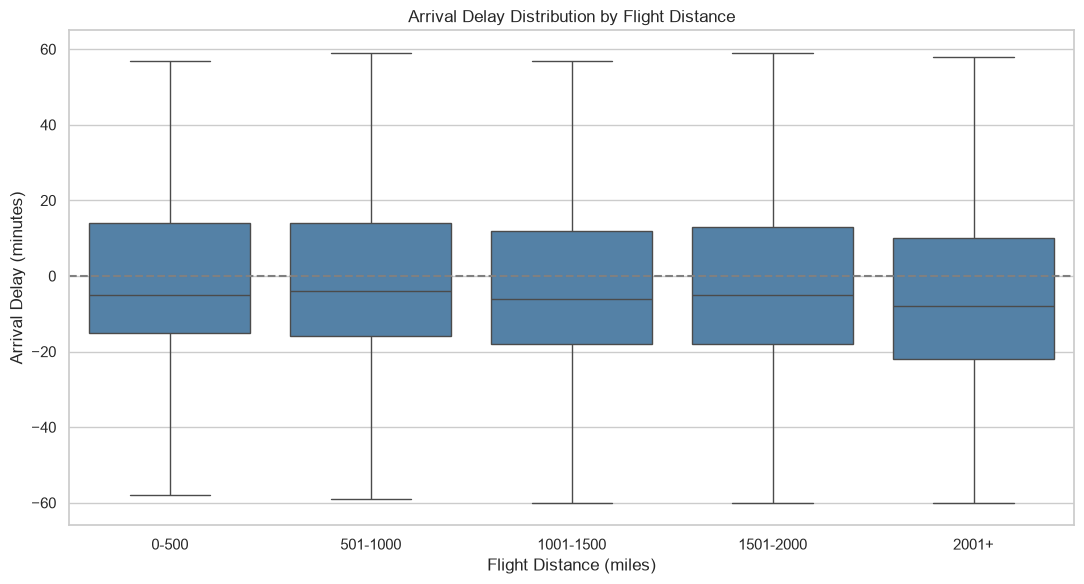

In [7]:
plot_data = distance_data[
    distance_data["arr_delay"].between(-60, 180)
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=plot_data,
    x="distance_group",
    y="arr_delay",
    order=distance_labels,
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay Distribution by Flight Distance",
    xlabel="Flight Distance (miles)",
    ylabel="Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Flight Distance vs. Arrival Delay

Explore the relationship between flight distance and arrival delay using the original continuous distance variable.

A random sample of flights is displayed to reduce overplotting. A LOWESS trend is added to examine possible nonlinear patterns.

The correlation coefficient is calculated using all valid observations.

Pearson correlation between distance and arrival delay: -0.0619


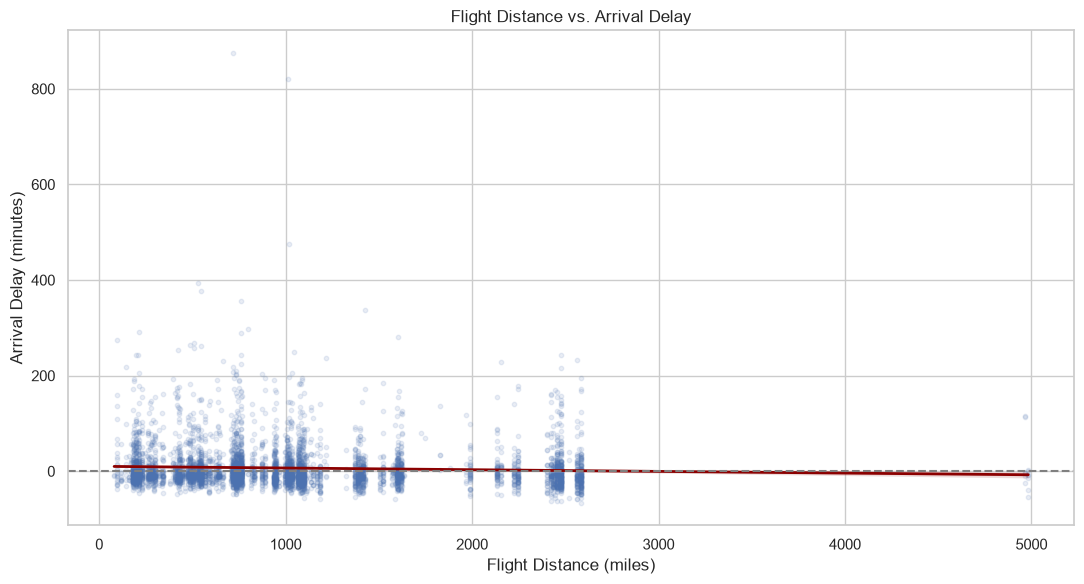

In [14]:
# Use a reproducible sample for visualization
scatter_sample = distance_data.sample(
    n=min(5000, len(distance_data)),
    random_state=42
)

# Pearson correlation using all valid observations
correlation = distance_data[
    ["distance", "arr_delay"]
].corr().loc["distance", "arr_delay"]

print(
    f"Pearson correlation between distance and arrival delay: "
    f"{correlation:.4f}"
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.regplot(
    data=scatter_sample,
    x="distance",
    y="arr_delay",
    lowess=False,
    scatter_kws={"alpha": 0.12, "s": 10},
    line_kws={"color": "darkred", "linewidth": 2},
    ax=ax
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Flight Distance vs. Arrival Delay",
    xlabel="Flight Distance (miles)",
    ylabel="Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_vs_arrival_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Extreme Delays and Sample Sizes

Examine the number and percentage of flights delayed more than 120 minutes and compare sample sizes across distance groups.

This helps us identify groups with more severe delays and evaluate whether group comparisons may be affected by unequal sample sizes.

In [15]:
extreme_stats = (
    distance_data.groupby(
        "distance_group",
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Delays_Over_120=lambda x: (x > 120).sum(),
        Extreme_Delay_Pct=lambda x: (x > 120).mean() * 100,
        Maximum_Delay="max"
    )
    .reindex(distance_labels)
)

extreme_stats["Share_of_Total_Pct"] = (
    extreme_stats["Flights"] / len(distance_data) * 100
)

display(extreme_stats.round(2))

,Flights,Delays_Over_120,Extreme_Delay_Pct,Maximum_Delay,Share_of_Total_Pct
distance_group,,,,,
0-500,76775,2594,3.38,1127.0,23.45
501-1000,105819,3664,3.46,1109.0,32.33
1001-1500,72798,2029,2.79,931.0,22.24
1501-2000,20772,527,2.54,847.0,6.35
2001+,51182,1220,2.38,1272.0,15.64


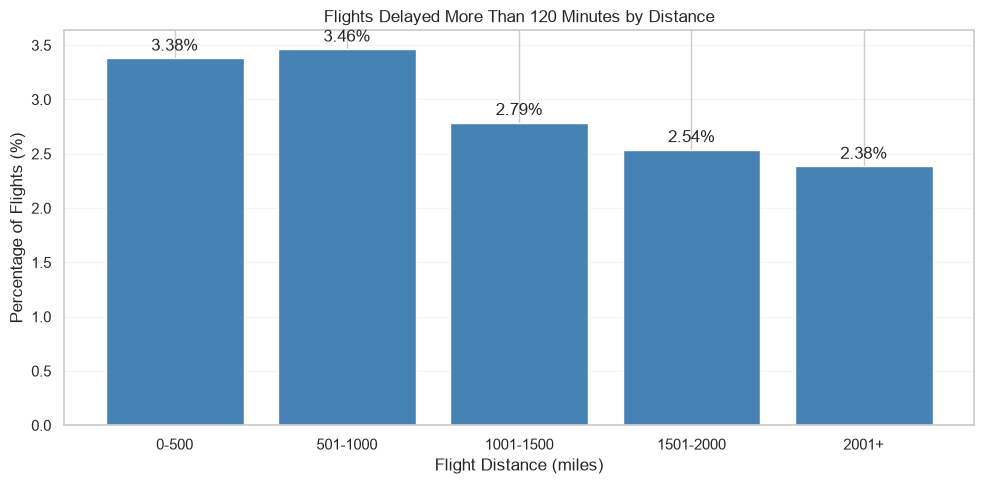

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    extreme_stats.index,
    extreme_stats["Extreme_Delay_Pct"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Flights Delayed More Than 120 Minutes by Distance",
    xlabel="Flight Distance (miles)",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "distance_extreme_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Save distance analysis tables

distance_summary.round(2).to_csv(
    table_dir / "distance_descriptive_statistics.csv"
)

distance_stats.round(2).to_csv(
    table_dir / "distance_group_statistics.csv",
    index_label="distance_group"
)

extreme_stats.round(2).to_csv(
    table_dir / "distance_extreme_delays.csv",
    index_label="distance_group"
)

print("Saved: results/tables/distance_descriptive_statistics.csv")
print("Saved: results/tables/distance_group_statistics.csv")
print("Saved: results/tables/distance_extreme_delays.csv")

Saved: results/tables/distance_descriptive_statistics.csv
Saved: results/tables/distance_group_statistics.csv
Saved: results/tables/distance_extreme_delays.csv


## 9. Key Findings and Limitations

Summarize the main relationships between flight distance and arrival delays, and discuss the limitations of this exploratory analysis.

In [18]:
highest_mean = distance_stats["Mean"].idxmax()
lowest_mean = distance_stats["Mean"].idxmin()

highest_15 = distance_stats["Delay_Over_15_Pct"].idxmax()
lowest_15 = distance_stats["Delay_Over_15_Pct"].idxmin()

highest_60 = distance_stats["Delay_Over_60_Pct"].idxmax()
highest_120 = distance_stats["Delay_Over_120_Pct"].idxmax()

print(
    f"Overall mean arrival delay: "
    f"{distance_data['arr_delay'].mean():.2f} minutes"
)

print(
    f"Overall median arrival delay: "
    f"{distance_data['arr_delay'].median():.2f} minutes"
)

print(
    f"\nHighest mean delay: {highest_mean} "
    f"({distance_stats.loc[highest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"Lowest mean delay: {lowest_mean} "
    f"({distance_stats.loc[lowest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"\nHighest >15 min delay rate: {highest_15} "
    f"({distance_stats.loc[highest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Lowest >15 min delay rate: {lowest_15} "
    f"({distance_stats.loc[lowest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Highest >60 min delay rate: {highest_60} "
    f"({distance_stats.loc[highest_60, 'Delay_Over_60_Pct']:.2f}%)"
)

print(
    f"Highest >120 min delay rate: {highest_120} "
    f"({distance_stats.loc[highest_120, 'Delay_Over_120_Pct']:.2f}%)"
)

print(f"\nPearson correlation: {correlation:.4f}")

Overall mean arrival delay: 6.90 minutes
Overall median arrival delay: -5.00 minutes

Highest mean delay: 0-500 (9.26 minutes)
Lowest mean delay: 2001+ (1.31 minutes)

Highest >15 min delay rate: 501-1000 (24.83%)
Lowest >15 min delay rate: 2001+ (20.93%)
Highest >60 min delay rate: 0-500 (9.70%)
Highest >120 min delay rate: 501-1000 (3.46%)

Pearson correlation: -0.0619


## 9. Key Findings and Limitations

### Key Findings

The overall mean arrival delay was 6.90 minutes, while the median was −5 minutes. This suggests that some large delays increased the average.

Flights traveling 0–500 miles had the highest mean arrival delay (9.26 minutes), while flights traveling over 2,000 miles had the lowest (1.31 minutes).

The 501–1,000 mile group had the highest percentage of flights delayed more than 15 minutes (24.83%) and 120 minutes (3.46%). The 0–500 mile group had the highest percentage of flights delayed more than 60 minutes (9.70%).

The Pearson correlation between flight distance and arrival delay was −0.0619, indicating a very weak negative linear relationship.

Overall, shorter-distance flights tended to have higher average arrival delays, but flight distance alone showed little linear association with arrival delay.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

The distance groups were created for exploratory purposes, and the number of flights may differ across groups.

Other factors, such as airline, season, scheduled departure time, airport, and weather conditions, may also be associated with arrival delays. These factors were not controlled for in this analysis.

Extreme delays may influence the mean arrival delay. In addition, these descriptive results do not establish that flight distance causes arrival delays. Further statistical analysis is needed to examine these relationships.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

Flight and weather data were merged using the origin airport and hourly timestamp. Flights with missing arrival delay values were excluded during data cleaning.

No missing values were found in the flight distance or arrival delay columns in the cleaned dataset, so no additional missing-value treatment was needed for this analysis.

Flight distances were divided into five groups using the original distance analysis categories. The same cleaned dataset was used for all descriptive statistics and visualizations to maintain consistency.